<h1 style="color:red" align = center>INTRODUCTION TO MACHINE LEARNING</h1>
<h1 style="color:red" align = center> ChurnGuard GROUP PROJECT </h1>
<h2 style="color:red"align = center>Instructor: Dr. Khaled Mohamad</h2>

### TEAM ROLES:

<table style="text-align:left">
<tr>
    <th>Member</th>
    <th>Student ID</th>
    <th>Role</th>
</tr>
<tr>
    <td>Tairuly Nursat</td>
    <td>24B031110</td>
    <td>EDA Lead</td>
</tr>
<tr>
    <td>Gaukarbek Akmaral</td>
    <td>24B031725</td>
    <td>Modelling Lead</td>
</tr>
<tr>
    <td>Bayandiev Alibek</td>
    <td>24B031696</td>
    <td>Report & Presentation Lead</td>
</tr>
</table>

In [1]:
# Imports of dataset and needed libraries. 
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns
import numpy as np
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

import warnings 
warnings.filterwarnings("ignore")

df = pd.read_csv("Customer_Churn.csv") 

<h2 style="color:blue">1.1 Dataset Overview.</h2>

We used the **Iranian Churn** dataset from the UCI Machine Learning Repository:
`https://archive.ics.uci.edu/dataset/563/iranian+churn+dat`.
<br>The dataset contains customer information from an Iranian telecommunications company. It has **3150 rows** and **14 columns**: 13 features and one target column(`Churn`).

**Problem type:** classification.

**Target variable:** `Churn` - indicates whether a customer left the company `(Churn = 1)` or stayed `(Churn = 0)`.



In [2]:
display(df.shape)
display(df.head())

(3150, 14)

,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
0,8,0,38,0,4370,71,5,17,3,1,1,30,197.640,0
1,0,0,39,0,318,5,7,4,2,1,2,25,46.035,0
2,10,0,37,0,2453,60,359,24,3,1,1,30,1536.520,0
3,10,0,38,0,4198,66,1,35,1,1,1,15,240.020,0
4,3,0,38,0,2393,58,2,33,1,1,1,15,145.805,0


<h3 style="color:blue">1.2.1 Data Types Overview</h3>

<h4 style="color:orange">Our data consists of numerical dtypes.</h4>


<h3 style="color:blue">Data Types and Column Classification</h3>

We can divide the columns in our dataset into three types:

<h4 style="color:brown">1. Binary (True/False, represented by integers)</h4>

- **1/0 notation:**
  - `Complains` (had complaints / did not have complaints)
  - `Churn` (left / stayed)

- **2/1 notation:**
  - `Tariff Plan` (contractual / pay-as-you-go)
  - `Status` (non-active / active)

<h4 style="color:brown">2. Common Integers</h4>

- **With limits:**
  - `Charge Amount` (min: 0, max: 10)
  - `Age Group` (min: 1, max: 5)

- **Without limits:**
  - `Age`
  - `Call Failures`
  - `Subscription Length` (months)
  - `Seconds of Use`
  - `Frequency of Use` (total number of calls)
  - `Frequency of SMS`
  - `Distinct Called Numbers`

<h4 style="color:brown">3. Float</h4>

- `Customer Value` (the calculated value of a customer)

---

In summary, we can divide our dataframe columns into three types: **Binary, Integer, and Float**. As you can see above, this is a more detailed explanation of columns that are not easy to understand or have specific limitations.

The first problem we noticed with the dataframe was its lack of consistency. For example, calling `Call Failure` may cause an error because the original dataset contains two spaces in its column name, while `Tariff Plan` contains only one. We also noticed an inconsistency in binary notation: some columns use the 1/0 notation, while others use 2/1 notation. There is a certain logic behind this (1/0 represents T/F, while 2/1 is used for other categories), but overall, it is confusing. These inconsistencies can cause our group to waste time or make mistakes in the program logic.

<p style="color:#F59E0B"><b>We should try to standardize everything.</b></p>

Therefore, we will fix these problems by modifying our data during the data-cleaning process.

---

We can observe that `df.info()` and `df.describe()` confirm our statements about the division of numerical data types.



We can clearly see that the minimum and maximum values for Common Integers with limits match the values mentioned above. We can also observe from the minimum and maximum values that we really have Binary-type columns.

Moreover, we can see that the mean (average) is higher than the median (50%) for `Charge Amount`, `Seconds of Use`, and other columns (except `Subscription Length` and `Age Group`). This means that most of our columns are likely to be positively skewed.



We can also see that there are **no missing values**.

---

<h4 style="color:blue">Our Main Prediction</h4>

Our main prediction is that customers who **have filed complaints** and **experienced more call failures** are **more likely to churn** than customers who have not complained and experienced fewer call failures.

<h4 style="color:brown">Detailed Analysis of the Target Variable (<code>Churn</code>) is provided in Section 3.</h4>


In [3]:
df.info()
display(df.describe()) 
display(df.dtypes)
display(df.isnull().sum())

print("Complains unique values:", df["Complains"].unique())
print("Churn unique values:", df["Churn"].unique())
print("Tariff Plan unique values:", df["Tariff Plan"].unique())
print("Status unique values:", df["Status"].unique())
print("Charge  Amount unique values:", np.sort(df["Charge  Amount"].unique()))
print("Age Group unique values:", np.sort(df["Age Group"].unique()))

<class 'pandas.DataFrame'>
RangeIndex: 3150 entries, 0 to 3149
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Call  Failure            3150 non-null   int64  
 1   Complains                3150 non-null   int64  
 2   Subscription  Length     3150 non-null   int64  
 3   Charge  Amount           3150 non-null   int64  
 4   Seconds of Use           3150 non-null   int64  
 5   Frequency of use         3150 non-null   int64  
 6   Frequency of SMS         3150 non-null   int64  
 7   Distinct Called Numbers  3150 non-null   int64  
 8   Age Group                3150 non-null   int64  
 9   Tariff Plan              3150 non-null   int64  
 10  Status                   3150 non-null   int64  
 11  Age                      3150 non-null   int64  
 12  Customer Value           3150 non-null   float64
 13  Churn                    3150 non-null   int64  
dtypes: float64(1), int64(13)
memory usa

,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
count,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000
mean,7.627937,0.076508,32.541905,0.942857,4472.459683,69.460635,73.174921,23.509841,2.826032,1.077778,1.248254,30.998413,470.972916,0.157143
std,7.263886,0.265851,8.573482,1.521072,4197.908687,57.413308,112.237560,17.217337,0.892555,0.267864,0.432069,8.831095,517.015433,0.363993
min,0.000000,0.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,15.000000,0.000000,0.000000
25%,1.000000,0.000000,30.000000,0.000000,1391.250000,27.000000,6.000000,10.000000,2.000000,1.000000,1.000000,25.000000,113.801250,0.000000
50%,6.000000,0.000000,35.000000,0.000000,2990.000000,54.000000,21.000000,21.000000,3.000000,1.000000,1.000000,30.000000,228.480000,0.000000
75%,12.000000,0.000000,38.000000,1.000000,6478.250000,95.000000,87.000000,34.000000,3.000000,1.000000,1.000000,30.000000,788.388750,0.000000
max,36.000000,1.000000,47.000000,10.000000,17090.000000,255.000000,522.000000,97.000000,5.000000,2.000000,2.000000,55.000000,2165.280000,1.000000


Call  Failure                int64
Complains                    int64
Subscription  Length         int64
Charge  Amount               int64
Seconds of Use               int64
Frequency of use             int64
Frequency of SMS             int64
Distinct Called Numbers      int64
Age Group                    int64
Tariff Plan                  int64
Status                       int64
Age                          int64
Customer Value             float64
Churn                        int64
dtype: object

Call  Failure              0
Complains                  0
Subscription  Length       0
Charge  Amount             0
Seconds of Use             0
Frequency of use           0
Frequency of SMS           0
Distinct Called Numbers    0
Age Group                  0
Tariff Plan                0
Status                     0
Age                        0
Customer Value             0
Churn                      0
dtype: int64

Complains unique values: [0 1]
Churn unique values: [0 1]
Tariff Plan unique values: [1 2]
Status unique values: [1 2]
Charge  Amount unique values: [ 0  1  2  3  4  5  6  7  8  9 10]
Age Group unique values: [1 2 3 4 5]



<h2 style="color:blue">1.2 Target variable analysis</h2>

Our target variable is <code>Churn</code>, which indicates whether a customer left the service or stayed.

- <code>0</code> — Customer stayed.
- <code>1</code> — Customer left.

As we can see, the dataset contains **3,150 customers**:
- **2,655 customers (84.29%)** stayed.
- **495 customers (15.71%)** left.

In [4]:
display(df["Churn"].value_counts())

Churn
0    2655
1     495
Name: count, dtype: int64

<h2 style="color:blue">1.3 Data cleaning</h2>

<p style="color:orange">We will <b>divide our dataframe into 3 parts:</b></p>

- `df`: the original dataframe without any changes. It will be used to analyze the dataframe before cleaning.
- `df_analyze`: the dataframe cleaned of duplicates. It will be used to analyze the dataframe after cleaning.
- `df_clean`: `df_clean` is a copy of `df_analyze` with the `Age` column removed and the `High Failure` feature added. Skewness is corrected later in Section 4.1 using the Yeo-Johnson transformation.

<h3 style="color:blue">1.3.1 Missing-values and Duplicates check</h3>

In [5]:
display(df.isnull().sum())
display(df.duplicated().sum())
df[df.duplicated()]

Call  Failure              0
Complains                  0
Subscription  Length       0
Charge  Amount             0
Seconds of Use             0
Frequency of use           0
Frequency of SMS           0
Distinct Called Numbers    0
Age Group                  0
Tariff Plan                0
Status                     0
Age                        0
Customer Value             0
Churn                      0
dtype: int64

np.int64(300)

,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
518,0,0,37,0,0,0,0,0,2,1,2,25,0.00,1
628,0,0,35,0,0,0,0,0,2,1,2,25,0.00,1
718,0,0,37,0,0,0,0,0,2,1,2,25,0.00,1
728,0,0,36,0,0,0,0,0,3,1,2,30,0.00,1
901,0,0,38,0,0,0,0,0,2,1,2,25,0.00,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3145,21,0,19,2,6697,147,92,44,2,2,1,25,721.98,0
3146,17,0,17,1,9237,177,80,42,5,1,1,55,261.21,0
3147,13,0,18,4,3157,51,38,21,3,1,1,30,280.32,0
3148,7,0,11,2,4695,46,222,12,3,1,1,30,1077.64,0


<h3 style="color:blue">1.3.2 Duplicates cleaning</h3>

In [6]:
df_analyze = df.copy()


df_analyze.drop_duplicates(inplace=True)
df_analyze.rename(columns={'Call  Failure': 'Call Failure', 'Subscription  Length': 'Subscription Length', 'Charge  Amount': 'Charge Amount'}, inplace=True)

display(df_analyze.shape)
df_analyze.head()

(2850, 14)

,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
0,8,0,38,0,4370,71,5,17,3,1,1,30,197.640,0
1,0,0,39,0,318,5,7,4,2,1,2,25,46.035,0
2,10,0,37,0,2453,60,359,24,3,1,1,30,1536.520,0
3,10,0,38,0,4198,66,1,35,1,1,1,15,240.020,0
4,3,0,38,0,2393,58,2,33,1,1,1,15,145.805,0


<h3 style="color:blue">1.3.3 Skewness check</h3>

In [7]:
df_clean = df_analyze.copy()
df_analyze.skew()

Call Failure               1.067233
Complains                  3.080435
Subscription Length       -1.252843
Charge Amount              2.533804
Seconds of Use             1.314737
Frequency of use           1.145862
Frequency of SMS           1.971020
Distinct Called Numbers    1.039277
Age Group                  0.453043
Tariff Plan                3.089147
Status                     1.218203
Age                        1.223952
Customer Value             1.422214
Churn                      1.891937
dtype: float64

We can divide **skewness** into:
- **Skewness < 0:** negative (left skew)
- **Skewness > 0:** positive (right skew)

Skewness represents the symmetry of our data:
- **Skewness = 0:** symmetric
- **0 < Skewness < 0.5** or **0 > Skewness > -0.5:** approximately symmetric
- **0.5 < Skewness < 1** or **-0.5 > Skewness > -1:** moderately skewed
- **Skewness > 1** or **Skewness < -1:** highly skewed (asymmetric)

We should try to avoid asymmetry in our data. Most of the columns have **skewness > 1**, except `Subscription Length` which has **skewness < -1** and `Age Group` (**0.453043**). If we train our model on **Linear Regression** or **KNN**, it may give us inaccurate results, because these algorithms are sensitive to extreme values. For example, we have a dataframe about customers and their cats. If we want to use a KNN model, and in the dataframe most customers have 0 or 1 cats, but some customers have 10 cats, then, because KNN picks the nearest neighbors, its predictions can jump because of the customers with 10 cats.

<p style="color:orange"> Later (<b>Section 5</b>), we will solve this problem by applying <b>Yeo-Johnson transformation</b> to all columns except binary types (because they consist of 0/1) and Age Group (because it has acceptable skewness). The Yeo-Johnson transformation works for both positive and negative skew, so we can just use it, but its flaw is that it needs to be fitted on the training data first.</p>

<p style="color:brown"> But why do we use <b>Yeo-Johnson transformation</b> instead of log1p or power methods? It's mainly because log1p and other transformations give us unsatisfying skewness correction (> 0.5 or < -0.5), so we used the more advanced <b>Yeo-Johnson transformation</b>.</p>

<h3 style="color:blue">1.3.4 Cloned data</h3>

In [8]:
df_clean = df_clean.drop(columns=["Age"])

We dropped `Age` because it is redundant with `Age Group`, preventing multicollinearity. Our decision will be confirmed later after checking **heatmap**(**0.96**).

<h3 style="color:blue">1.3.5 Ghost Customers Problem</h3>

In [9]:
df_ghost = df_analyze[df_analyze["Customer Value"] == 0]
display(df_ghost["Churn"].value_counts())
df_ghost[(df_ghost["Frequency of use"] > 0) | (df_ghost["Frequency of SMS"] > 0) | (df_ghost["Seconds of Use"] > 0) | (df_ghost["Distinct Called Numbers"] > 0) | (df_ghost["Call Failure"] > 0)]

Churn
1    44
0    41
Name: count, dtype: int64

,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn


While investigating the values in our dataframe, We found 85 customers with a Customer Value of 0. Their `Frequency of use`, `Frequency of SMS`, `Seconds of Use`, `Distinct Called Numbers` and `Call Failure` were also 0.

We then checked the `Churn` values for these rows to determine whether they should be removed. The results showed that **44 customers had churned** (`Churn = 1`), while **41 customers had stayed** (`Churn = 0`). This data holds about **10%(44)** of our `Churn = 1` cases, so we can't delete it.

<p style="color:orange"><b>Therefore, we decided not to remove these rows and keep them in our dataset.</b></p>

<h3 style="color:blue">1.3.6 Class Distribution</h3>

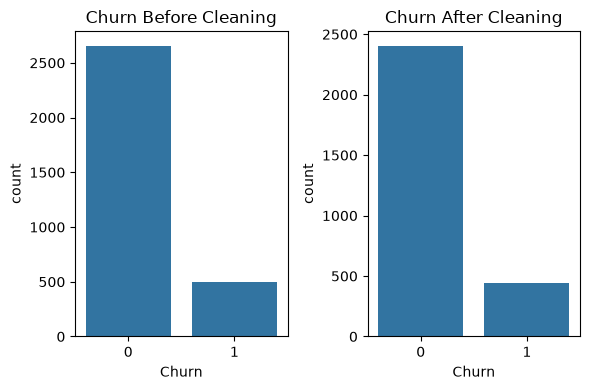

'Before:'

Churn
0    2655
1     495
Name: count, dtype: int64

'After:'

Churn
0    2404
1     446
Name: count, dtype: int64

In [10]:
plt.figure(figsize=(6, 4))

plt.subplot(1, 2, 1)
sns.countplot(x="Churn", data=df)
plt.title("Churn Before Cleaning")

plt.subplot(1, 2, 2)
sns.countplot(x="Churn", data=df_analyze)
plt.title("Churn After Cleaning")

plt.tight_layout()
plt.show()

display("Before:", df["Churn"].value_counts())
display("After:", df_analyze["Churn"].value_counts())




We can clearly see that the class proportions before and after cleaning are practically identical. The main difference is that the cleaned dataset contains **300 fewer rows**.

Before cleaning:
- `Churn = 0`: 2,655 customers
- `Churn = 1`: 495 customers

After cleaning:
- `Churn = 0`: 2,404 customers
- `Churn = 1`: 446 customers

Overall, the percentages have barely changed. The proportion of customers who churned was approximately **15.71% before cleaning** and **15.65% after cleaning**. Therefore, the difference is only about **0.06 percentage points**, which means that the class distribution remained almost unchanged after data cleaning.

<p style="color:orange"><b>Important:</b> Our dataset has an imbalanced target variable because the number of customers who stayed (2,404, about 84.4%) is significantly higher than the number of customers who left (446, about 15.6%).</p>

This class imbalance may affect our machine learning model. Therefore, in Week 3, we should consider using a stratified train/test split and evaluating the model with metrics such as **F1-score**, rather than relying only on accuracy.


<h3 style="color:blue">1.3.7 Overall Conclusion</h3>




We checked the dataframe for:

- *Missing values:* **0 missing values**

There are no missing values, so there is no reason to delete any rows for this reason.

<p style="color:orange"><b>No imputation strategy is required because there are no missing values. Therefore, there are no rows that need to be modified through imputation.</b></p>

- *Duplicates:* **300 duplicate rows**

We need to prevent potential data leakage and problems caused by duplicate rows. We will solve this problem by deleting duplicates.

After cleaning our data, the dataset now has **2,850 rows instead of 3,150**.

<table>
<tr>
<th></th>
<th>Before</th>
<th>After</th>
</tr>
<tr>
<td>Rows</td>
<td>3,150 rows</td>
<td>2,850 rows</td>
</tr>
<tr>
<td>Percentage of original data</td>
<td>100%</td>
<td>90.5%</td>
</tr>
<tr>
<td>Churned customers</td>
<td>495</td>
<td>446</td>
</tr>
<tr>
<td>Churn rate</td>
<td>15.7%</td>
<td>15.6%</td>
</tr>
</table>

Also, we thought there could be a **hidden problem with Ghost Customers** (customers who have 0 values in `Frequency of use`, `Frequency of SMS`, and `Customer Value`), because they may lead to **data leakage**.

Moreover, we understood that `Age` is **redundant data**, which may lead to **multicollinearity**. So we dropped it only in `df_clean`.

<h2 style="color:blue">2. Hypothesis Testing and Churn analysis</h2>




We hypothesized that customers who **have filed complaints** and **experienced more call failures** are **more likely to churn** than customers who have not complained and experienced fewer call failures.

It is difficult to visualize `Call Failure`, so we created a new column called `High Failure`. This means that the dataset now has **15 columns instead of 14**.



In [11]:
df_analyze["Churn"].value_counts()

Churn
0    2404
1     446
Name: count, dtype: int64

<h3 style="color:blue">2.1 Churn X Complains connection</h3>

<Axes: xlabel='Complains', ylabel='Churn'>

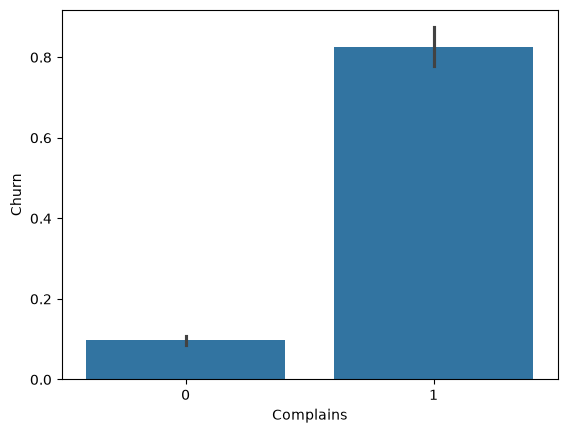

In [12]:
sns.barplot(data=df_analyze, x='Complains', y='Churn')


<h3 style="color:blue">2.1 Churn vs. Complains Connection</h3>



Our bar plot visualization of `Complains` against `Churn` shows that **complaints have a strong relationship with customer churn**.

The difference between customers who filed complaints and those who did not is significant — approximately **0.7** in the average `Churn` value. This difference is clearly visible in the binary `Churn` variable.
 
<p style="color:orange"><b>Customers who filed complaints are much more likely to churn than customers who did not.</b></p>


<h3 style="color:blue">2.2 Churn X High Failure connection</h3>

<Axes: xlabel='High Failure', ylabel='Churn'>

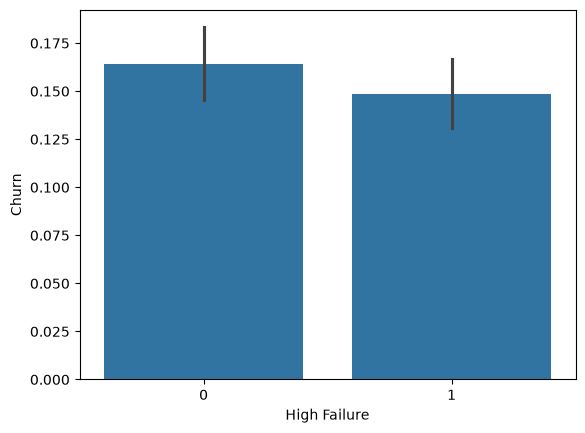

In [13]:
df_analyze["High Failure"] = (df_analyze["Call Failure"] > (df_analyze["Call Failure"].median())).astype("int")
df_clean["High Failure"] = df_analyze["High Failure"]
sns.barplot(data=df_analyze, x='High Failure', y='Churn')


<h3 style="color:blue">2.2 Churn vs. High Failure Connection</h3>



Our bar plot visualization of `High Failure` against `Churn` shows that **high call failure does not appear to have a strong relationship with customer churn**.

The difference between the average `Churn` values for customers with low and high call failure is approximately **0.015**. This difference is relatively small.

<p style="color:orange"><b>This result may indicate a problem with our initial hypothesis, as high call failure does not seem to be a strong predictor of customer churn in our dataset.</b></p>


<h3 style="color:blue">2.3 Crosstab Analysis with both Complains and High Failure and its Analysis</h3>

We created a crosstab using both `Complains` and `High Failure`, and we can clearly observe the following:
- Customers who **did not experience many call failures** and **did not have any complaints** have a churn rate of only **12%** (11.6%).
- Customers who **did not experience many call failures** but **had complaints** have a churn rate of **96%** (96.3%).
- Customers who **experienced many call failures** but **did not have any complaints** have a churn rate of **8%** (7.7%).
- Customers who **experienced many call failures** and **had complaints** have a churn rate of **75%** (75.0%).


<p style="color:orange"><b>The results show that complaints are a much stronger indicator of churn than high call failure alone. Customers who filed complaints had a high churn rate regardless of their call failure level.</b></p>


In [14]:
crossCompAFail = pd.crosstab(df_analyze["Churn"], [df_analyze["High Failure"],df_analyze["Complains"]] , margins = True)
crossCompAFail

High Failure     0         1        All
Complains        0   1     0    1      
Churn                                  
0             1216   3  1148   37  2404
1              160  79    96  111   446
All           1376  82  1244  148  2850

<h3 style="color:blue">2.4 Visualization of all relationships in dataframe</h3>

<h3 style="color:orange">Let's visualize all relationships in dataframe with heatmap to view relationships between each column</h3>

<Axes: >

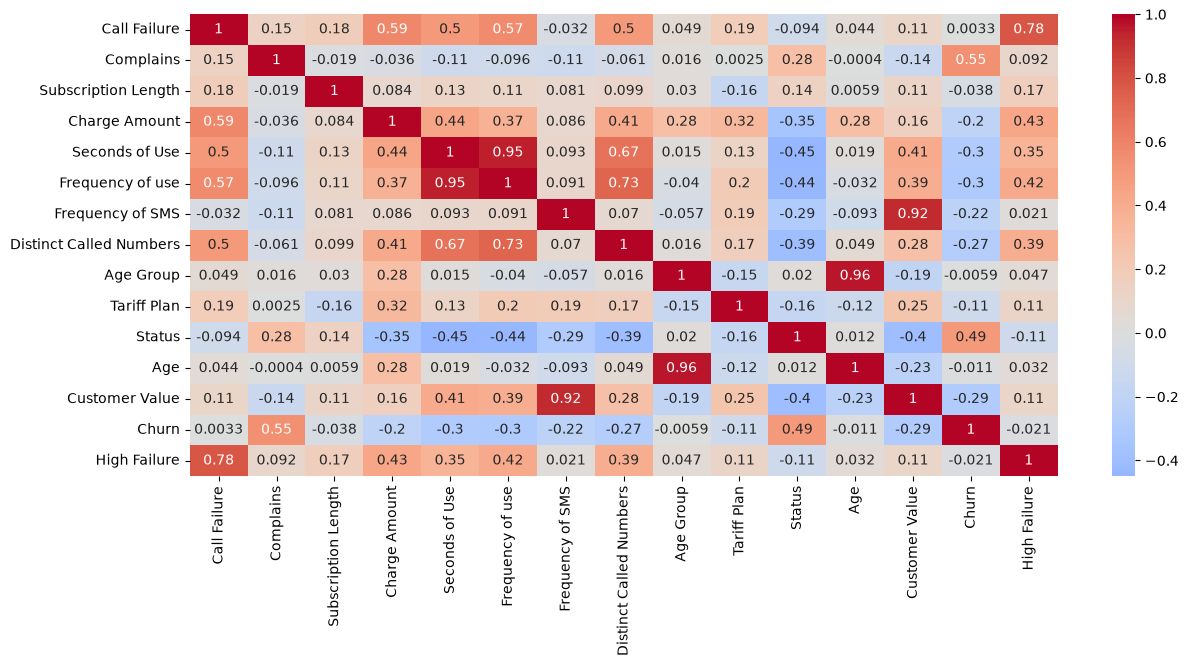

In [15]:
plt.figure(figsize=(14,6))
plt.subplot(1,1,1)
numeric_cols = df_analyze.columns
sns.heatmap(df_analyze[numeric_cols].corr(), annot=True, cmap = 'coolwarm', center = 0)

Our heatmap shows how every column relates to every other column. We can divide these connections into 3 types:

- There are positive connections (>0.1) like `Call Failure` X `High Failure` (**0.78**) and `Frequency of use` X `Seconds of Use` (**0.95**), etc. They show that if one column's value rises, it's more likely that the other column's value will rise too.
- There are near-zero connections (>-0.1 and <0.1) like `Age Group` X `Churn` (**-0.0059**) and `Frequency of SMS` X `Call Failure` (**-0.032**), etc. They show practically no relationship at all.
- There are negative connections (<-0.1) like `Status` X `Charge Amount` (**-0.35**) and `Churn` X `Frequency of use` (**-0.3**), etc. They show that if one column's value rises, it's more likely that the other column's value will fall.

There are columns that are very similar to each other, like `Frequency of use` X `Seconds of Use` (**0.95**), `Customer Value` X `Frequency of SMS` (**0.92**) and `Age Group` X `Age` (**0.96**). Their information have many similarities. `Age Group` X `Age` (**0.96**) is actually **redundant data**.

Let's concentrate our attention on Churn connections. We can see that most of the columns are **informative** (<-0.1 or >0.1) for Churn: `Complains` (**0.55**), `Charge Amount` (**-0.2**), `Seconds of Use` (**-0.3**), `Frequency of use` (**-0.3**), `Frequency of SMS` (**-0.22**), `Distinct Called Numbers` (**-0.27**), `Tariff Plan` (**-0.11**), `Status` (**0.49**), `Customer Value` (**-0.29**). Also there are **noninformative** (>-0.1 and <0.1) columns: `Call Failure` (**0.0033**), `Subscription Length` (**-0.038**), `Age Group` (**-0.0059**), `Age` (**-0.011**), `High Failure` (**-0.021**).

<p style="color:#B91C1C">
So we can say that most of the columns are connected to Churn, but most of those connections aren't very strong. Columns such as Seconds of Use (-0.3), Frequency of use (-0.3), Status (0.49) and Complains (0.55) are likely to be the most useful for predicting our target variable Churn. We can only hypothesise that customers churn because they aren't very active or because their complaints weren't solved properly. But this doesn't prove that customers will churn because of these parameters.</p>

<h3 style="color:blue">2.5 Conclusion for our Hypothesis</h3>

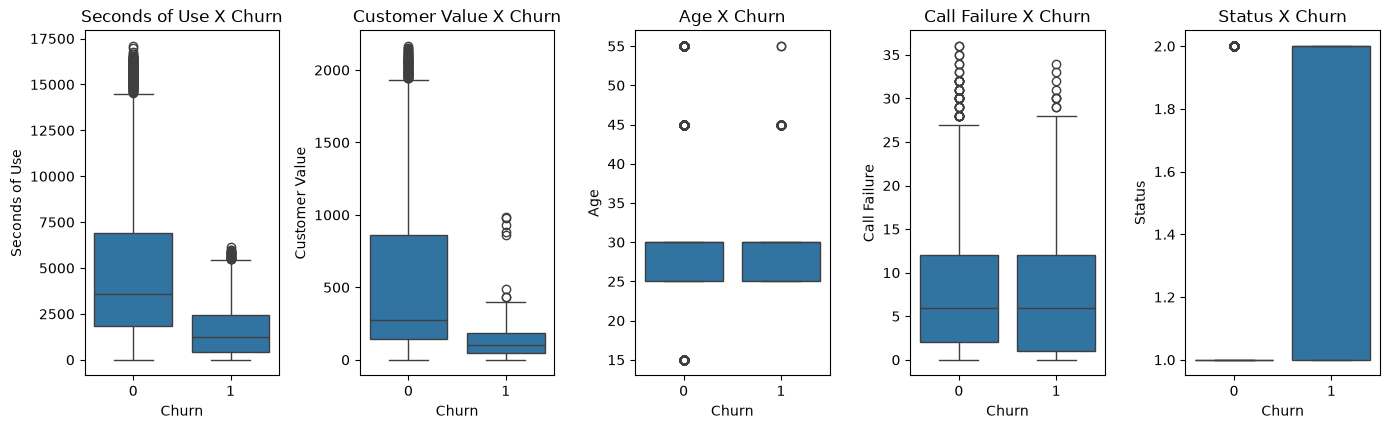

Status is 1 and Churn is 0 cases count: 2045
Status is 1 and Churn is 1 cases count: 121
Status is 2 and Churn is 0 cases count: 359
Status is 2 and Churn is 1 cases count: 325


In [16]:
plt.figure(figsize=(14,8))

plt.subplot(2,5,1)
sns.boxplot(data=df_analyze, x="Churn", y="Seconds of Use")
plt.title("Seconds of Use X Churn")


plt.subplot(2,5,2)
sns.boxplot(data=df_analyze, x="Churn", y="Customer Value")
plt.title("Customer Value X Churn")


plt.subplot(2,5,3)
sns.boxplot(data=df_analyze, x="Churn", y="Age")
plt.title("Age X Churn")


plt.subplot(2,5,4)
sns.boxplot(data=df_analyze, x="Churn", y="Call Failure")
plt.title("Call Failure X Churn")


plt.subplot(2,5,5)
sns.boxplot(data=df_analyze, x="Churn", y="Status")
plt.title("Status X Churn")

plt.tight_layout()
plt.show()

print("Status is 1 and Churn is 0 cases count:", len(df_analyze[(df_analyze["Status"] == 1) & (df_analyze["Churn"] == 0)]))
print("Status is 1 and Churn is 1 cases count:", len(df_analyze[(df_analyze["Status"] == 1) & (df_analyze["Churn"] == 1)]))
print("Status is 2 and Churn is 0 cases count:", len(df_analyze[(df_analyze["Status"] == 2) & (df_analyze["Churn"] == 0)]))
print("Status is 2 and Churn is 1 cases count:", len(df_analyze[(df_analyze["Status"] == 2) & (df_analyze["Churn"] == 1)]))

Our boxplots show how `Seconds of Use`, `Customer Value`, `Age`, `Call Failure` and `Status` relate to `Churn`. This also supports our findings.

- **Negative connection** (`Seconds of Use` (**-0.3**), `Customer Value` (**-0.29**)): the higher the value, the less likely the customer is to churn. For example, the median `Seconds of Use` is about 3,600 for customers who stayed and about 1,300 for customers who left.
- **Near-zero connection** (`Age` (**-0.011**), `Call Failure` (**0.0033**)): the boxes of both groups almost identical. For example, `Age` is between 25 and 30 for both groups, so there is no pattern.
- **Positive connection** (`Status` (**0.49**)): about half(325) of non-active customers (2) left, while only about 6%(**121**) of active customers (1) left.

As I said in heatmap overview `Seconds of Use`, `Customer Value` and `Status` are useful features for predicting churn(**informative**), while `Age` and `Call Failure` aren't so useful for it(**noninformative**).

<h3 style="color:blue">2.6 Conclusion for our Hypothesis</h3>

Our hypothesis is only partly true:
- **True:** We can observe that customers who *had any complaints* have a **higher percentage of Churn**.
- **False:** We can observe that even if customers *experienced many failures*, they still have a **lower percentage of Churn**.

<h3 style="color:blue">2.7 Why Our Hypothesis Is Only Partially Supported</h3>

<h3 style="color:orange">There are several possible reasons:</h3>

<ul>
<li style="color:#B91C1C">There is a possibility that this is because we concentrated only on the number of <code>Call  Failure</code>, not on the percentage of <code>Call  Failure</code> among <code>Frequency of use</code>.</li></ul>

The percetage for High Failure: 19.9 %
The percetage for Low Failure:  9.19 %
The percetage for df_analyze:      14.6 %


Text(0, 0.5, 'Number of customers')

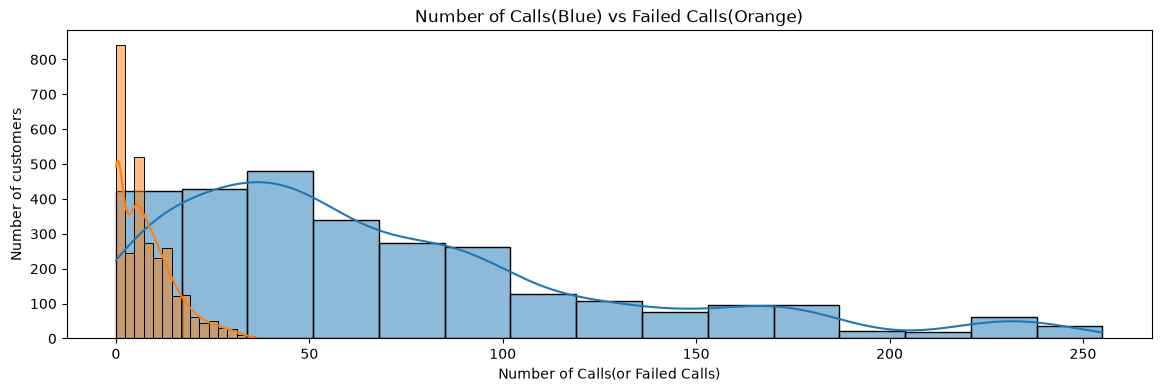

In [17]:
df_High_Failure = df_analyze[(df_analyze["High Failure"] == 1)]
df_Low_Failure = df_analyze[(df_analyze["High Failure"] == 0)]

df_High_Failure_no0Calls = df_High_Failure[df_High_Failure["Frequency of use"] != 0]
df_Low_Failure_no0Calls = df_Low_Failure[df_Low_Failure["Frequency of use"] != 0]
df_no0Calls = df_analyze[df_analyze["Frequency of use"] != 0]
avg_FailsperCalls_HighF = (df_High_Failure_no0Calls["Call Failure"]/df_High_Failure_no0Calls["Frequency of use"]).mean()
avg_FailsperCalls_LowF = (df_Low_Failure_no0Calls["Call Failure"]/df_Low_Failure_no0Calls["Frequency of use"]).mean()
avg_FailsperCalls_AllDf =(df_no0Calls["Call Failure"]/(df_no0Calls["Frequency of use"])).mean()

print("The percetage for High Failure:", (avg_FailsperCalls_HighF*100).round(1),"%")
print("The percetage for Low Failure: ", (avg_FailsperCalls_LowF*100).round(2),"%")
print("The percetage for df_analyze:     ", (avg_FailsperCalls_AllDf*100).round(1),"%")

plt.figure(figsize=(14,4))
plt.subplot(1,1,1)
sns.histplot(df_analyze["Frequency of use"], kde = True, bins = 15)
sns.histplot(df_analyze["Call Failure"], kde = True, bins = 15)
plt.title("Number of Calls(Blue) vs Failed Calls(Orange)") 
plt.xlabel("Number of Calls(or Failed Calls)")
plt.ylabel("Number of customers")


<p style="color:#A16207"><b>Histogram Breakdown</b></p>

These histograms show us the number of calls (blue) and failed calls (orange) per customer. We can observe the following trends:

- **For Calls:**
  - The maximum number of calls is slightly above 250.
  - Most customers make fewer than 100 calls.
  - The number of calls per customer initially increases slightly and then declines.
  - The maximum number of customers within a single bin is approximately 500.

- **For Failed Calls:**
  - The maximum number of failed calls is slightly below 40.
  - Most customers have fewer than 12 failed calls.
  - The number of failed calls per customer decreases as the number of failed calls increases.
  - The maximum number of customers within a single bin is approximately 500.

Although this histogram is not directly connected to `Churn`, it represents a **14.6%** failure rate across all normal calls.



<h4 style="color:brown">Conclusion</h4>

This does not appear to be the reason. Customers with `High Failure` also have a high percentage of failed calls (**19.9%**), while customers with `Low Failure` (`High Failure == 0`) have a much lower percentage of failed calls (**9.19%**). The overall average is 14.6%


---


<ul>
<li style="color:#B91C1C">Another possibility is that these customers are more loyal because their <code>Subscription Length</code> is higher, making it harder for them to switch providers.</li>
</ul>


In [18]:
print("Avg Subscription Length for High  Failure:", (df_High_Failure["Subscription Length"]).mean().round(1),"months")
print("Avg Subscription Length for Low  Failure: ", (df_Low_Failure["Subscription Length"]).mean().round(1),"months")
print("Avg Subscription Length for df_analyze:     ", (df_analyze["Subscription Length"]).mean().round(1),"months")

Avg Subscription Length for High  Failure: 33.9 months
Avg Subscription Length for Low  Failure:  31.0 months
Avg Subscription Length for df_analyze:      32.5 months



<h4 style="color:brown">Conclusion</h4>

This does not appear to be the reason. Customers have very similar `Subscription Length` values, with a difference of only **2.9 months** between the two groups.


---


<ul>
<li style="color:#B91C1C">Another possibility is that these customers are older (where <code>Age Group</code> ranges from 1 (youngest) to 5 (oldest)) and may not know how to switch providers, so they decide to stay.</li>
</ul>


In [19]:
print("Avg Age Group for High Failure:", (df_High_Failure["Age Group"]).mean().round(1))
print("Avg Age Group for Low Failure:", (df_Low_Failure["Age Group"]).mean().round(1))
print("Avg Age Group for whole df_analyze:", (df_analyze["Age Group"]).mean().round(1))

Avg Age Group for High Failure: 2.9
Avg Age Group for Low Failure: 2.8
Avg Age Group for whole df_analyze: 2.8



<h4 style="color:brown">Conclusion</h4>

This does not appear to be the reason. Customers have very similar `Age Group` values, with a difference of only **0.1** between the two groups.


---


<h4 style="color:blue">Visualizing the Remaining Possibilities with a Heatmap</h4>


<Axes: >

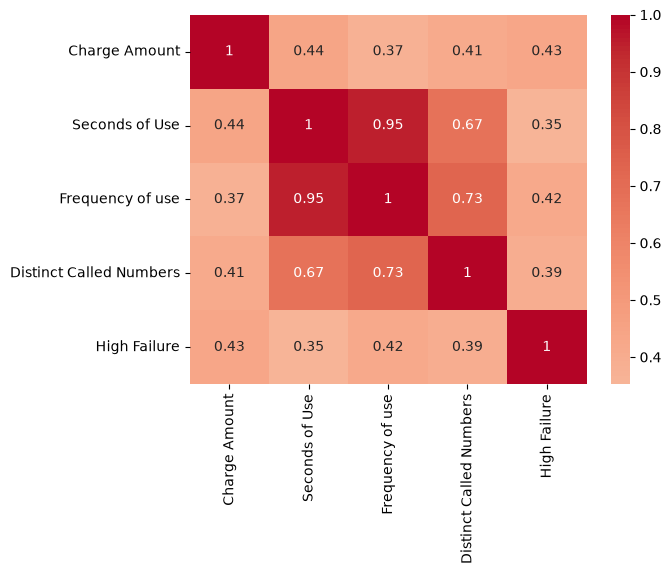

In [20]:
df_heat = df_analyze.copy()
df_heat.drop(columns=["Call Failure", "Complains", "Subscription Length", "Age Group", "Tariff Plan", "Status", "Age", "Customer Value", "Churn", "Frequency of SMS" ], inplace=True,             errors = "ignore")
numeric_cols = df_heat.columns
sns.heatmap(df_heat[numeric_cols].corr(), annot=True, cmap = 'coolwarm', center = 0)


<h4 style="color:brown">Conclusion</h4>

<p style="color:#A16207"><b> This may be one of the reasons.</b></p>

We can observe that almost all the selected columns (`Charge Amount`, `Seconds of Use`, `Frequency of Use`, and `Distinct Called Numbers`), except for `Frequency of SMS`, have a relatively strong positive correlation with `High Failure` (approximately **0.35–0.43**).

This suggests that these features are related to call activity. Therefore, customers may experience high call failure while still maintaining relatively high levels of call activity.


<hr>

<h2 style="color:blue">3. Feature Engineering</h2>



<h3 style="color:blue">3.1 Categorical Encoding</h3>

Tariff Plan and Status each have two categories. We changed their original codes from **1** and **2** to **0** and **1**.

In [21]:
df_model = df_clean.copy()

code_map = {1: 0, 2: 1}

df_model["Tariff Plan"] = df_model["Tariff Plan"].map(code_map)
df_model["Status"] = df_model["Status"].map(code_map)

encoding_counts = pd.DataFrame({"Tariff Plan":df_model["Tariff Plan"].value_counts(dropna=False),"Status":df_model["Status"].value_counts(dropna=False)})

display(encoding_counts.sort_index())

,Tariff Plan,Status
0,2621,2166
1,229,684


<p><i><b>Tariff Plan</i></b> values: 0 = Pay-as-you-go, 1 = Contractual.<br>
<i><b>Status</i></b> values: 0 = Active, 1 = Non-active.</p>

These features have only two categories. Therefore, one binary column per feature is enough. In Logistic Regression, it helps in comparing the category coded as 1 with the reference category coded as 0.

We plan to use **Logistic Regression** as our first model.
Features that have only two categories such as `Tariff Plan` and `Status` are each encoded as a single column. The model can compare contract-based plans with pay-as-you-go plans based on this column. It is the same case for decision trees which require a single split to partition the two.

For `Age Group` we decided to keep the feature with values in an ordered categorical scale of 1 to 5 from the youngest age to the oldest age. Encoding these values in a single column maintains their original ordering. In Logistic Regression, a change from group 1 to 2 has the same effect on the predicted log-odds of churn as a change from group 4 to 5, with other features held constant. One-hot encoding would let each group have its own effect. We chose to keep the ordered values for our first model.

Charge Amount has ordered levels from 0 to 10. We kept these levels in one column because a higher value represents a higher charge. In Section 4.1, we used the Yeo–Johnson transformation to reduce its skewness.

`Complains` is encoded in binary (0 for no complaints and 1 for complaints). We retained this.


<h3 style="color:blue">3.2 New feature: Failure Rate (row-wise, safe before the split)</h3>

In [22]:
df_analyze["Failure Rate"] =np.where(df_analyze["Frequency of use"]>0,df_analyze["Call Failure"]/ df_analyze["Frequency of use"],0)                       
df_model["Failure Rate"] = df_analyze["Failure Rate"]

print(df_analyze.groupby("Churn")["Failure Rate"].mean())
print("skew -", df_analyze["Failure Rate"].skew()," max -", df_analyze["Failure Rate"].max())

Churn
0    0.118637
1    0.258324
Name: Failure Rate, dtype: float64
skew - 4.664655426573184  max - 3.5


When comparing the mean of Failure Rates for stayers `(0.119)` to that of the leavers `(0.258)`, it was around **2.18** times higher in the leaver category. These findings align with our proposed link between churn and the failure of calls.

The feature shows high positive skewness, and the maximum recorded value is **3.5**. This means that at least one customer had more recorded call failures than recorded calls. The dataset description does not explain how failed attempts were counted, so we cannot reliably interpret this feature as the percentage of calls that failed. We use it only as the ratio of the two recorded counts. 

In cases where `no calls` have been recorded for the customer, we treat this ratio as `zero`, and the average values within each group also contain zeros.

<h4 style="color:brown">Conclusion</h4>
Failure Rate may carry information that raw Call Failure does not, because it accounts for how active the customer is. During the third week, we plan to compare performance with and without this feature and see how it helps improve predictions.


---

<h2 style="color:blue">4. Train/Test </h2>

<h3 style="color:blue">4.1 Splitting and Correcting Skewness</h3>

In [23]:
X = df_model[["Call Failure","Complains","Subscription Length","Charge Amount","Seconds of Use", "Frequency of use", "Frequency of SMS", "Distinct Called Numbers","Age Group", "Tariff Plan", "Status", "Customer Value", "High Failure","Failure Rate"]]
y = df_model["Churn"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("X_train", X_train.shape)
print("X_test", X_test.shape)
print("y_train", y_train.shape)
print("y_test", y_test.shape)

threshold = X_train["Call Failure"].median()
X_train["High Failure"] = (X_train["Call Failure"] > threshold).astype(int)
X_test["High Failure"] = (X_test["Call Failure"] > threshold).astype(int)

X_train_raw = X_train.copy()
high_skew = ["Subscription Length","Charge Amount","Seconds of Use","Frequency of use", "Distinct Called Numbers", "Customer Value", "Call Failure", "Frequency of SMS", "Failure Rate"]


for col in high_skew:
    X_train[col], lam = stats.yeojohnson(X_train[col])
    X_test[col] = stats.yeojohnson(X_test[col], lmbda=lam)

df_skew = pd.DataFrame([X_train_raw.skew(), X_train.skew(), X_test.skew()])
df_skew.insert(0, "State", ["Before", "Train (After)", "Test (After)"])
display(df_skew.head())

X_train (2280, 14)
X_test (570, 14)
y_train (2280,)
y_test (570,)


,State,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Customer Value,High Failure,Failure Rate
0,Before,1.109243,3.102723,-1.276443,2.545446,1.303090,1.144182,1.981104,1.039593,0.468767,3.147492,1.221747,1.420099,0.063231,4.857811
1,Train (After),-0.107849,3.102723,-0.378666,0.397763,-0.099914,-0.067194,-0.035683,-0.074645,0.468767,3.147492,1.221747,-0.036228,0.063231,0.215875
2,Test (After),-0.165059,3.002394,-0.256438,0.333611,-0.063481,-0.084363,-0.130256,-0.016589,0.374483,2.884180,1.207289,0.054900,-0.021109,0.130122


We split a population of 2,850 customers. We used **80% (2,280 customers)** for training and the remaining **20% (570 customers)** for testing. We used `stratify=y` so that the percentage of customers who left was about the same in both sets.

The training set median for call failures was set as the threshold for `High Failure`. If a customer had more call failures than this threshold, they received a value of 1, and 0 otherwise. We used the same threshold for test customers so that “high failure” had the same meaning in both groups.

We then applied the Yeo–Johnson transformation to nine features to reduce their skewness. For each feature, we found the transformation parameter using the training set and applied it to the test set. A skewness value closer to zero means the feature is less skewed. Results from the training set before and after transformation `Before` and `Train (After)` describe the same group. Similarly, the results after transformation on the test set are described in `Test (After)`.

<h4 style="color:brown">Conclusion</h4>
Our data split creates two distinct data sets that can be used in subsequent stages. We will use the training data set to determine the scaling of each selected feature, and we will apply the scaling to the test data set as well, in accordance with the method that we describe in the next section (4.2).

<h3 style="color:blue">4.2 Feature Scaling</h3>

Logistic Regression can benefit from feature scaling. For that, we chose `StandardScaler` to address the fact that our features have different ranges. This technique standardizes the features so one unit is equivalent to one training standard deviation. Because the scaling happens this way, the regularization term in our cost function penalizes coefficients on a comparable scale. `MinMaxScaler` is another option that scales the features to a common range (0-1), however, that scaling method isn't needed here.

In [24]:
binary_cols = ["Complains", "Tariff Plan", "Status", "High Failure"]
scale_cols = X_train.columns.drop(binary_cols)
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

scaler = StandardScaler()
scaler.fit(X_train[scale_cols])
X_train_scaled[scale_cols] = scaler.transform(X_train[scale_cols])
X_test_scaled[scale_cols] = scaler.transform(X_test[scale_cols])

scaling_check = pd.DataFrame({"Mean before": X_train[scale_cols].mean(), "Mean after": X_train_scaled[scale_cols].mean(),
                              "Std after": X_train_scaled[scale_cols].std(ddof=0)})
display(scaling_check.round(3))

,Mean before,Mean after,Std after
Call Failure,2.410,0.0,1.0
Subscription Length,2583.168,0.0,1.0
Charge Amount,0.262,0.0,1.0
Seconds of Use,48.201,0.0,1.0
Frequency of use,9.739,0.0,1.0
Frequency of SMS,3.388,0.0,1.0
Distinct Called Numbers,6.734,0.0,1.0
Age Group,2.837,-0.0,1.0
Customer Value,12.186,0.0,1.0
Failure Rate,0.075,-0.0,1.0


After scaling, all 10 selected features in the training set had a mean close to **0** and a standard deviation of **1**. For example, the mean `Failure Rate` before scaling was **0.075**,after scaling it equals to **0**. Values greater than zero mean their rate was above the training average, and a negative value means it was below.

<h4 style="color:brown">Conclusion</h4> We used the same training means and standard deviations to scale the test set. Both sets are now on the same scale for Logistic Regression.

<p style="color:#B91C1C">We needed to scale and skew data, so <code>train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)" </code> isn't exactly at the end, but near it.</p>